In [31]:
!mamba install pandas numpy matplotlib scipy seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns

print("Все библиотеки подключены!")

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.966 seconds
All requested packages already installed.
Все библиотеки подключены!


In [32]:
from IPython.display import display
import ipywidgets as widgets
import pandas as pd

# Создаём кнопку загрузки файла
uploader = widgets.FileUpload(
    accept=".csv",
    multiple=False
)

display(uploader)

FileUpload(value=(), accept='.csv', description='Upload')

In [33]:
# Получаем содержимое загруженного файла
uploaded_file = uploader.value

if isinstance(uploaded_file, dict):
    file_content = list(uploaded_file.values())[0]["content"]
else:
    file_content = uploaded_file[0]["content"]

# Загружаем данные непосредственно из памяти
from io import BytesIO

df = pd.read_csv(
    BytesIO(file_content),
    sep=";",
    decimal=","
)

print("Файл успешно загружен!")
print("Размер датасета:", df.shape)

display(df.head())

Файл успешно загружен!
Размер датасета: (5000, 14)


,customer_id,date,age,gender,region,traffic_source,campaign,time_on_site_s,pages_visited,converted,purchase_amount,num_items,delivery_time_days,satisfaction
0,2295,01.01.2025,30,Male,South,Organic,NaN,373.7,8,1,43.00,5,9,4.0
1,2903,01.01.2025,55,Female,South,PaidAds,CAMP3,1407.9,3,1,294.00,3,12,5.0
2,1922,01.01.2025,21,Female,North,Referral,NaN,493.0,5,1,81.55,4,14,4.0
3,3627,01.01.2025,44,Male,South,Organic,NaN,784.2,13,1,60.45,2,5,3.0
4,2605,01.01.2025,22,Male,East,Organic,NaN,1090.9,9,1,45.87,4,1,4.0


In [28]:
# Проверяем структуру датасета
print("Размер датасета:", df.shape)

print("\nПервые 5 строк:")
display(df.head())

print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isna().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

Размер датасета: (5000, 14)

Первые 5 строк:


,customer_id,date,age,gender,region,traffic_source,campaign,time_on_site_s,pages_visited,converted,purchase_amount,num_items,delivery_time_days,satisfaction
0,2295,01.01.2025,30,Male,South,Organic,NaN,373.7,8,1,43.00,5,9,4.0
1,2903,01.01.2025,55,Female,South,PaidAds,CAMP3,1407.9,3,1,294.00,3,12,5.0
2,1922,01.01.2025,21,Female,North,Referral,NaN,493.0,5,1,81.55,4,14,4.0
3,3627,01.01.2025,44,Male,South,Organic,NaN,784.2,13,1,60.45,2,5,3.0
4,2605,01.01.2025,22,Male,East,Organic,NaN,1090.9,9,1,45.87,4,1,4.0



Типы данных:
customer_id             int64
date                      str
age                     int64
gender                    str
region                    str
traffic_source            str
campaign                  str
time_on_site_s        float64
pages_visited           int64
converted               int64
purchase_amount       float64
num_items               int64
delivery_time_days      int64
satisfaction          float64
dtype: object

Количество пропусков:
customer_id              0
date                     0
age                      0
gender                   0
region                   0
traffic_source           0
campaign              3449
time_on_site_s           0
pages_visited            0
converted                0
purchase_amount          0
num_items                0
delivery_time_days       0
satisfaction          3180
dtype: int64

Количество дубликатов:
0


In [34]:
# Преобразуем дату в формат datetime
df["date"] = pd.to_datetime(
    df["date"],
    dayfirst=True
)

# Проверяем конверсию
conversion = df["converted"].mean() * 100

print(f"Конверсия: {conversion:.2f}%")

# Проверяем количество покупателей
print("Количество покупателей:", df["converted"].sum())

# Проверяем период наблюдений
print("Начало периода:", df["date"].min())
print("Конец периода:", df["date"].max())

Конверсия: 36.40%
Количество покупателей: 1820
Начало периода: 2025-01-01 00:00:00
Конец периода: 2025-06-29 00:00:00


In [30]:
# Выбираем ключевые переменные
variables = [
    "purchase_amount",
    "time_on_site_s",
    "pages_visited",
    "delivery_time_days",
    "satisfaction"
]

# Создаем таблицу статистики
stats = df[variables].agg(
    ["count", "mean", "median", "var", "std"]
).T

# Добавляем коэффициент вариации
stats["cv_%"] = stats["std"] / stats["mean"] * 100

display(stats.round(2))

,count,mean,median,var,std,cv_%
purchase_amount,5000.0,34.93,0.00,7615.05,87.26,249.84
time_on_site_s,5000.0,361.87,305.45,65282.46,255.50,70.61
pages_visited,5000.0,5.99,6.00,5.06,2.25,37.58
delivery_time_days,5000.0,2.87,0.00,20.93,4.57,159.30
satisfaction,1820.0,4.10,4.00,0.41,0.64,15.73


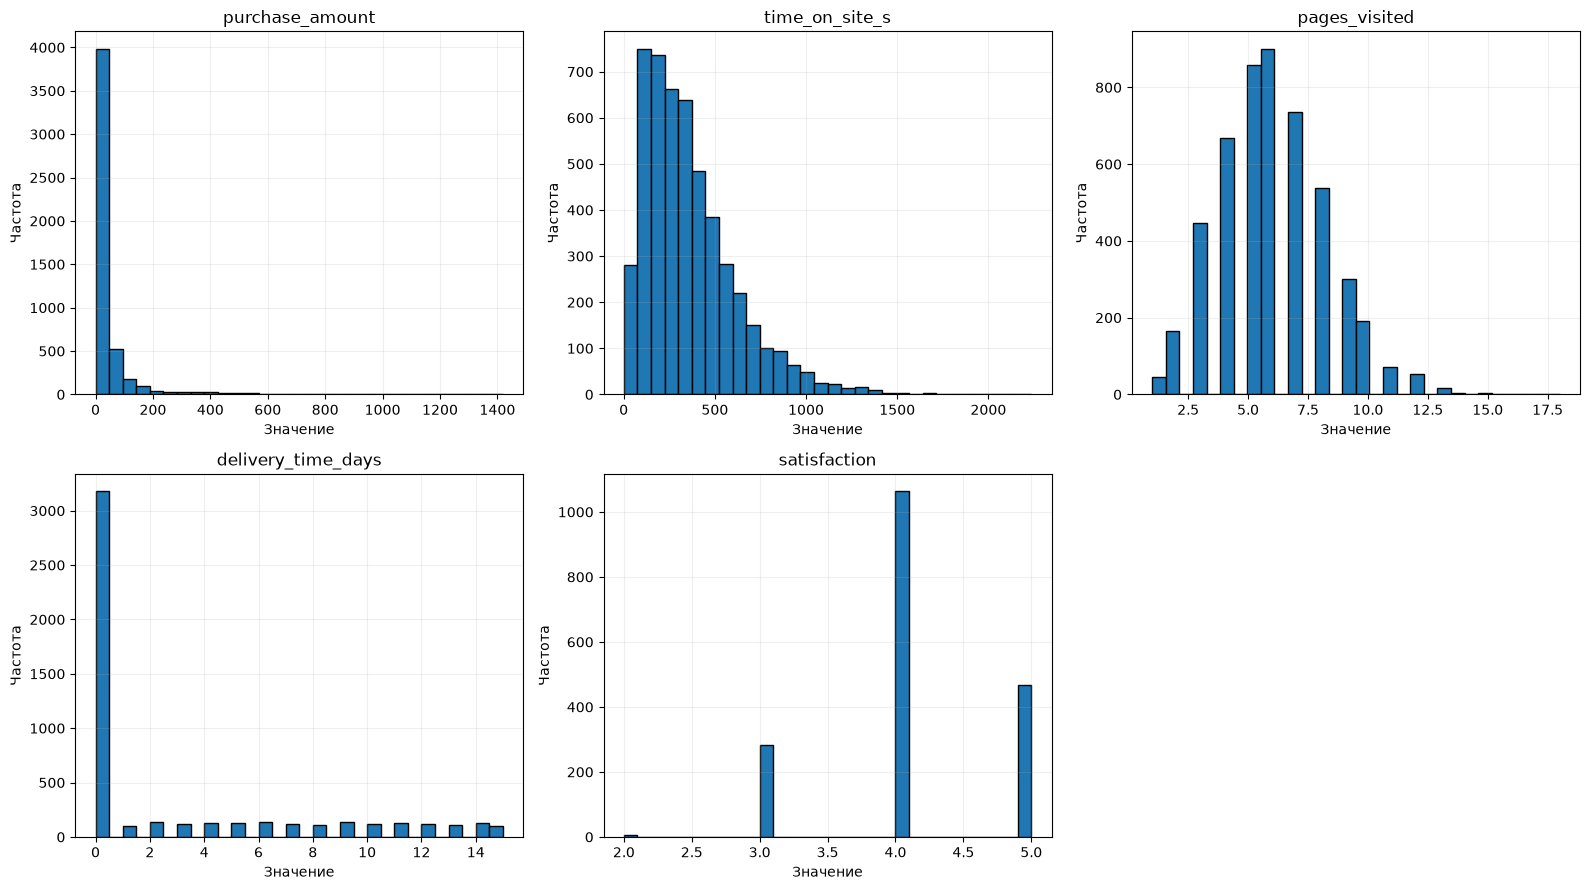

In [35]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, column in zip(axes.flat, variables):

    data = df[column].dropna()

    ax.hist(data, bins=30, edgecolor="black")

    ax.set_title(column)
    ax.set_xlabel("Значение")
    ax.set_ylabel("Частота")
    ax.grid(alpha=0.2)

axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [36]:

import pandas as pd
import numpy as np

# Фиксируем размер выборки
N = len(df)
n = 800

# Фиксируем генератор случайных чисел,
# чтобы результаты можно было воспроизвести
rng = np.random.default_rng(42)

# ==========================================
# 1. ПРОСТАЯ СЛУЧАЙНАЯ ВЫБОРКА
# ==========================================

sample_random = df.sample(
    n=n,
    replace=False,
    random_state=42
)

# ==========================================
# 2. СТРАТИФИЦИРОВАННАЯ ВЫБОРКА ПО РЕГИОНАМ
# ==========================================

# Создаём отдельный признак для пропущенных регионов
df_strat = df.copy()

df_strat["_region"] = (
    df_strat["region"]
    .fillna("Не указан")
    .astype(str)
)

# Считаем количество пользователей в каждом регионе
region_sizes = df_strat["_region"].value_counts()

# Рассчитываем пропорциональное количество
# наблюдений для каждого региона
exact_allocation = region_sizes / N * n

# Берём целые части
allocation = np.floor(exact_allocation).astype(int)

# Сколько наблюдений осталось распределить
remaining = n - allocation.sum()

# Распределяем остаток регионам с наибольшими дробными частями
fractions = exact_allocation - allocation

for region in fractions.sort_values(ascending=False).index[:remaining]:
    allocation.loc[region] += 1

# Формируем стратифицированную выборку
stratified_parts = []

for region, group in df_strat.groupby("_region"):
    number = allocation.loc[region]

    if number > 0:
        stratified_parts.append(
            group.sample(
                n=number,
                random_state=42
            )
        )

sample_stratified = pd.concat(stratified_parts)

# Убираем технический столбец
sample_stratified = sample_stratified.drop(columns="_region")

# ==========================================
# 3. СИСТЕМАТИЧЕСКАЯ ВЫБОРКА
# ==========================================

# Шаг отбора
k = N // n

# Случайная начальная позиция
start = rng.integers(0, k)

# Выбираем каждого k-го пользователя
systematic_indices = np.arange(start, start + n * k, k)

sample_systematic = df.iloc[systematic_indices].copy()

# ==========================================
# ПРОВЕРЯЕМ РАЗМЕРЫ ВЫБОРОК
# ==========================================

print("Размер генеральной совокупности:", N)
print("Шаг систематической выборки:", k)
print("Начальная позиция:", start)

print("\nРазмеры выборок:")
print("Случайная:", len(sample_random))
print("Стратифицированная:", len(sample_stratified))
print("Систематическая:", len(sample_systematic))


Размер генеральной совокупности: 5000
Шаг систематической выборки: 6
Начальная позиция: 0

Размеры выборок:
Случайная: 800
Стратифицированная: 800
Систематическая: 800


In [37]:

# Функция расчёта показателей
def calculate_metrics(data, name):

    return {
        "Выборка": name,

        "Количество наблюдений": len(data),

        "Средний чек": data["purchase_amount"].mean(),

        "Стандартное отклонение": (
            data["purchase_amount"].std()
        ),

        "Конверсия, %": (
            data["converted"].mean() * 100
        ),

        "Медианный чек": (
            data["purchase_amount"].median()
        )
    }


# Рассчитываем показатели генеральной совокупности
population_metrics = calculate_metrics(
    df, "Генеральная совокупность"
)

# Рассчитываем показатели трёх выборок
results = [
    population_metrics,

    calculate_metrics(
        sample_random, "Случайная"
    ),

    calculate_metrics(
        sample_stratified, "Стратифицированная"
    ),

    calculate_metrics(
        sample_systematic, "Систематическая"
    )
]

# Создаём итоговую таблицу
comparison = pd.DataFrame(results)

print("СРАВНЕНИЕ ВЫБОРОК С ГЕНЕРАЛЬНОЙ СОВОКУПНОСТЬЮ")

display(comparison.round(2))


СРАВНЕНИЕ ВЫБОРОК С ГЕНЕРАЛЬНОЙ СОВОКУПНОСТЬЮ


,Выборка,Количество наблюдений,Средний чек,Стандартное отклонение,"Конверсия, %",Медианный чек
0,Генеральная совокупность,5000,34.93,87.26,36.40,0.0
1,Случайная,800,29.78,73.54,33.88,0.0
2,Стратифицированная,800,38.38,98.07,37.50,0.0
3,Систематическая,800,34.30,84.19,36.25,0.0


In [38]:

# Доли регионов в генеральной совокупности
population_regions = (
    df["region"]
    .fillna("Не указан")
    .value_counts(normalize=True)
    * 100
)

# Доли регионов в стратифицированной выборке
sample_regions = (
    sample_stratified["region"]
    .fillna("Не указан")
    .value_counts(normalize=True)
    * 100
)

# Объединяем результаты
region_comparison = pd.DataFrame({
    "Генеральная совокупность, %": population_regions,
    "Стратифицированная выборка, %": sample_regions
}).fillna(0)

region_comparison["Разница, п.п."] = (
    region_comparison["Стратифицированная выборка, %"]
    - region_comparison["Генеральная совокупность, %"]
)

display(region_comparison.round(2))


,"Генеральная совокупность, %","Стратифицированная выборка, %","Разница, п.п."
region,,,
East,31.58,31.62,0.04
South,24.70,24.62,-0.07
North,23.50,23.50,0.00
West,20.22,20.25,0.03


In [39]:
# Средний чек в генеральной совокупности
population_mean = df["purchase_amount"].mean()

# Словарь с тремя сформированными выборками
samples = {
    "Случайная": sample_random,
    "Стратифицированная": sample_stratified,
    "Систематическая": sample_systematic
}

# Список для результатов
representativeness_results = []

for name, sample in samples.items():

    # Средний чек в выборке
    sample_mean = sample["purchase_amount"].mean()

    # Отклонение от генеральной совокупности
    deviation = sample_mean - population_mean

    # Относительное отклонение в процентах
    relative_deviation = abs(deviation) / abs(population_mean) * 100

    representativeness_results.append({
        "Метод отбора": name,
        "Средний чек": sample_mean,
        "Отклонение": deviation,
        "Относительное отклонение, %": relative_deviation
    })

# Формируем итоговую таблицу
representativeness = pd.DataFrame(representativeness_results)

# Сортируем от наиболее репрезентативной выборки к наименее
representativeness = representativeness.sort_values(
    by="Относительное отклонение, %"
)

display(representativeness.round(2))

,Метод отбора,Средний чек,Отклонение,"Относительное отклонение, %"
2,Систематическая,34.30,-0.63,1.80
1,Стратифицированная,38.38,3.45,9.88
0,Случайная,29.78,-5.15,14.73


In [40]:
import numpy as np
import pandas as pd

# Параметры расчёта
N = len(df)
z = 1.96  # Квантиль нормального распределения для 95% доверия


# Функция расчёта доверительного интервала для среднего чека
def mean_confidence_interval(data):
    values = data["purchase_amount"].dropna()

    n = len(values)
    mean = values.mean()
    std = values.std(ddof=1)

    # Поправка на конечность генеральной совокупности
    fpc = np.sqrt((N - n) / (N - 1))

    margin = z * std / np.sqrt(n) * fpc

    return mean, mean - margin, mean + margin


# Функция расчёта доверительного интервала Уилсона для конверсии
def wilson_interval(data):
    values = data["converted"].dropna()

    n = len(values)
    p = values.mean()

    denominator = 1 + z**2 / n

    center = (p + z**2 / (2 * n)) / denominator

    margin = (
        z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
        / denominator
    )

    return p * 100, (center - margin) * 100, (center + margin) * 100


# Список выборок для сравнения
samples = {
    "Случайная": sample_random,
    "Стратифицированная": sample_stratified,
    "Систематическая": sample_systematic
}

# Рассчитываем интервалы
ci_results = []

for name, sample in samples.items():

    mean, mean_low, mean_high = mean_confidence_interval(sample)

    conversion, conv_low, conv_high = wilson_interval(sample)

    ci_results.append({
        "Метод отбора": name,
        "Средний чек": mean,
        "Нижняя граница среднего": mean_low,
        "Верхняя граница среднего": mean_high,
        "Конверсия, %": conversion,
        "Нижняя граница конверсии": conv_low,
        "Верхняя граница конверсии": conv_high
    })

ci_table = pd.DataFrame(ci_results)

display(ci_table.round(2))

,Метод отбора,Средний чек,Нижняя граница среднего,Верхняя граница среднего,"Конверсия, %",Нижняя граница конверсии,Верхняя граница конверсии
0,Случайная,29.78,25.11,34.45,33.88,30.68,37.22
1,Стратифицированная,38.38,32.15,44.61,37.50,34.21,40.91
2,Систематическая,34.30,28.95,39.65,36.25,32.99,39.64


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Значения среднего чека по всей генеральной совокупности
population = df["purchase_amount"].dropna().to_numpy()

# Параметры генеральной совокупности
population_mean = population.mean()
population_std = population.std(ddof=0)
N = len(population)

# Размеры выборок
sample_sizes = [5, 30, 100]

# Количество повторений
num_simulations = 1000

# Генератор случайных чисел
rng = np.random.default_rng(42)

# Здесь будем хранить результаты
sample_means = {}

# Повторяем отбор 1000 раз для каждого размера выборки
for n in sample_sizes:

    means = []

    for _ in range(num_simulations):

        # Отбираем наблюдения без возвращения
        sample = rng.choice(population, size=n, replace=False)

        # Рассчитываем средний чек выборки
        means.append(sample.mean())

    sample_means[n] = np.array(means)

print("Средний чек генеральной совокупности:", round(population_mean, 2))

for n in sample_sizes:
    print(
        f"Размер выборки {n}: "
        f"среднее выборочных средних = {sample_means[n].mean():.2f}"
    )

Средний чек генеральной совокупности: 34.93
Размер выборки 5: среднее выборочных средних = 36.05
Размер выборки 30: среднее выборочных средних = 33.87
Размер выборки 100: среднее выборочных средних = 34.92


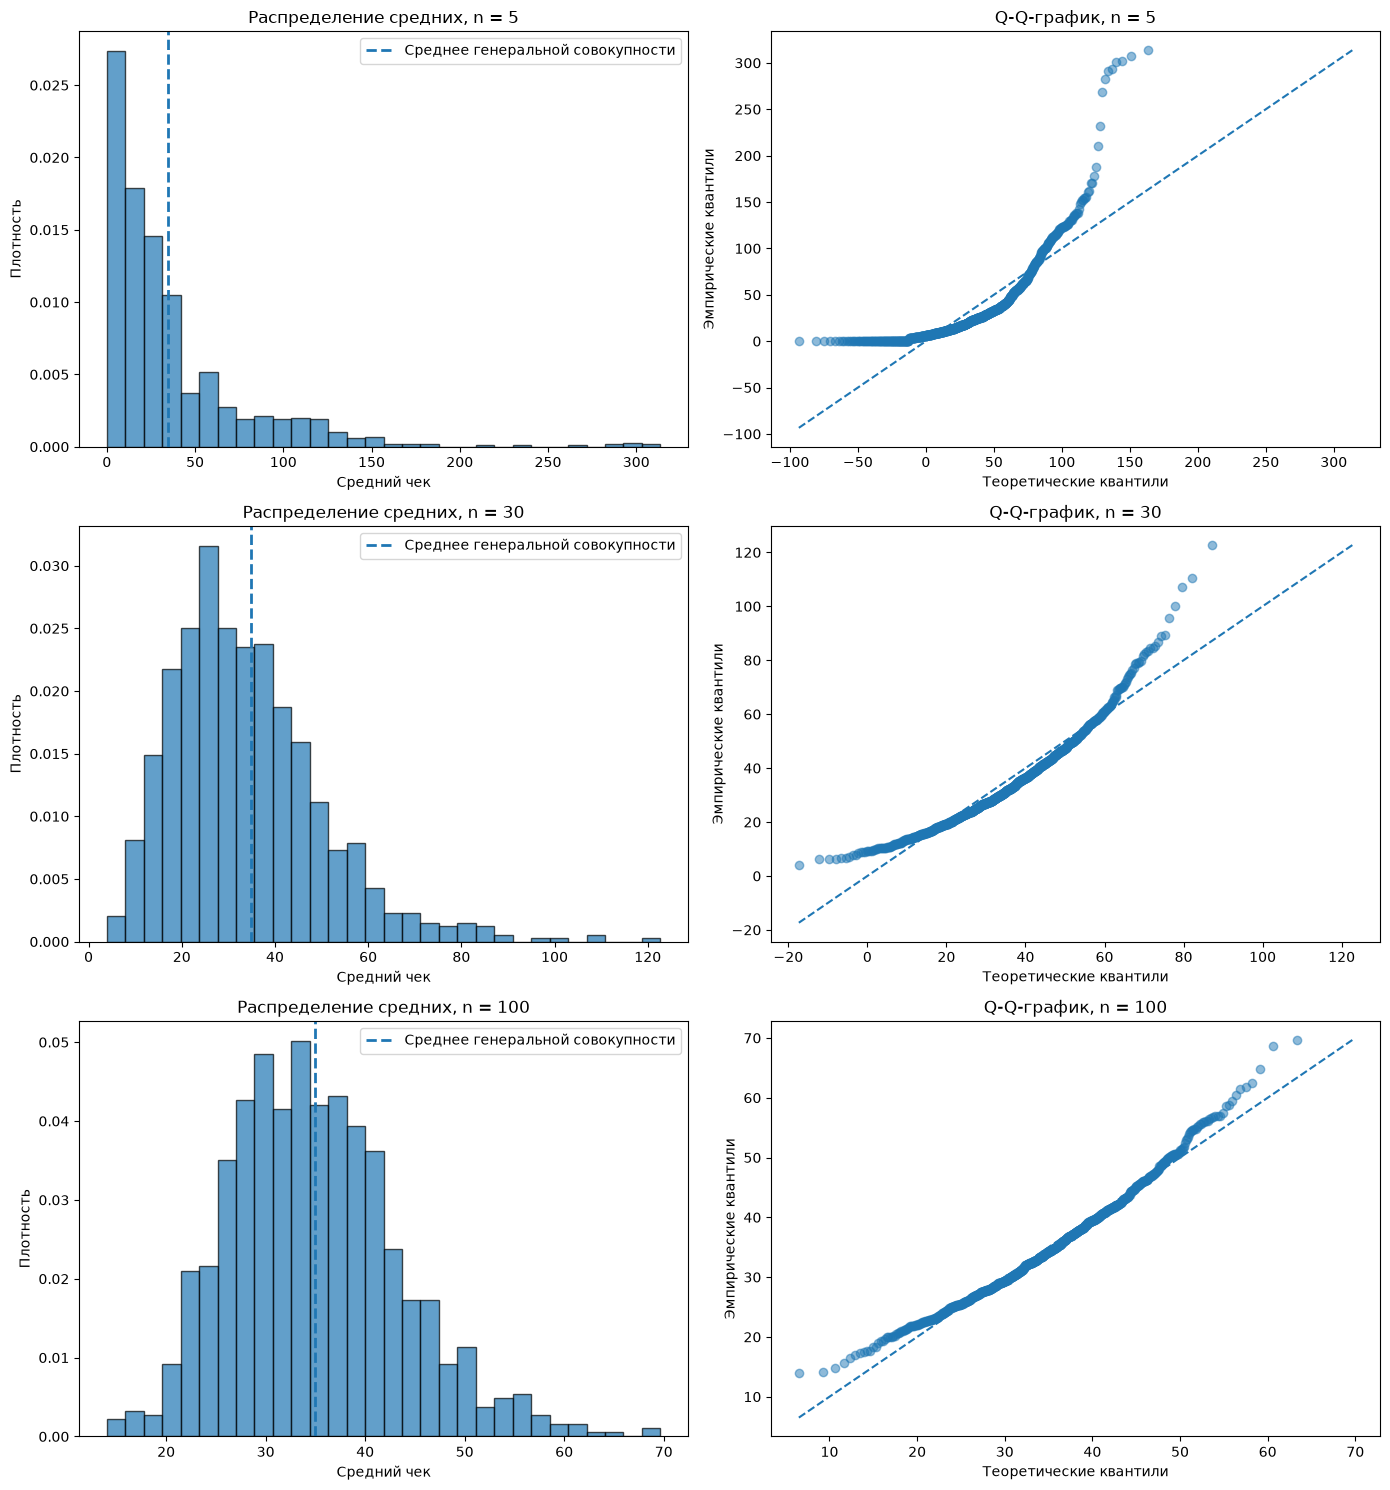

In [42]:
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for i, n in enumerate(sample_sizes):

    means = sample_means[n]

    # Поправка на конечность генеральной совокупности
    fpc = np.sqrt((N - n) / (N - 1))

    # Теоретическая стандартная ошибка среднего
    theoretical_se = population_std / np.sqrt(n) * fpc

    # Гистограмма выборочных средних
    axes[i, 0].hist(
        means,
        bins=30,
        density=True,
        alpha=0.7,
        edgecolor="black"
    )

    # Вертикальная линия — среднее генеральной совокупности
    axes[i, 0].axvline(
        population_mean,
        linestyle="--",
        linewidth=2,
        label="Среднее генеральной совокупности"
    )

    axes[i, 0].set_title(f"Распределение средних, n = {n}")
    axes[i, 0].set_xlabel("Средний чек")
    axes[i, 0].set_ylabel("Плотность")
    axes[i, 0].legend()

    # Q-Q-график относительно теоретического нормального распределения
    theoretical_quantiles = stats.norm.ppf(
        (np.arange(1, num_simulations + 1) - 0.5) / num_simulations,
        loc=population_mean,
        scale=theoretical_se
    )

    empirical_quantiles = np.sort(means)

    axes[i, 1].scatter(
        theoretical_quantiles,
        empirical_quantiles,
        alpha=0.5
    )

    # Диагональная линия идеального совпадения
    min_value = min(theoretical_quantiles.min(), empirical_quantiles.min())
    max_value = max(theoretical_quantiles.max(), empirical_quantiles.max())

    axes[i, 1].plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    axes[i, 1].set_title(f"Q-Q-график, n = {n}")
    axes[i, 1].set_xlabel("Теоретические квантили")
    axes[i, 1].set_ylabel("Эмпирические квантили")

plt.tight_layout()
plt.show()

In [43]:
variance_results = []

for n in sample_sizes:

    means = sample_means[n]

    # Фактическая дисперсия 1000 выборочных средних
    empirical_variance = np.var(means, ddof=1)

    # Теоретическая дисперсия с поправкой на конечность
    fpc = np.sqrt((N - n) / (N - 1))
    theoretical_variance = (
        population_std**2 / n
    ) * fpc**2

    variance_results.append({
        "Размер выборки": n,
        "Среднее выборочных средних": means.mean(),
        "Дисперсия выборочных средних": empirical_variance,
        "Теоретическая дисперсия": theoretical_variance
    })

variance_table = pd.DataFrame(variance_results)

display(variance_table.round(3))

,Размер выборки,Среднее выборочных средних,Дисперсия выборочных средних,Теоретическая дисперсия
0,5,36.046,1860.662,1521.487
1,30,33.874,259.457,252.312
2,100,34.921,73.681,74.627


Количество покупателей: 1820
Средний чек: 95.96
Медианный чек: 52.88
Минимальный чек: 1.07
Максимальный чек: 1419.3


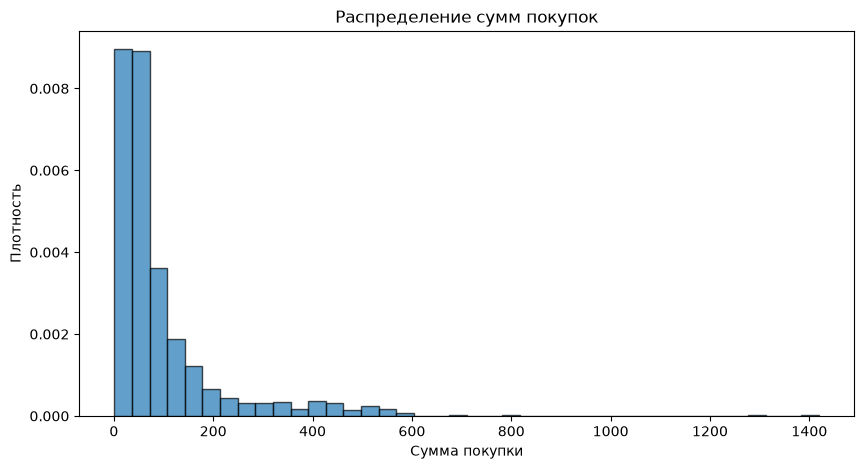

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Оставляем только клиентов, совершивших покупку
buyers = df.loc[
    (df["converted"] == 1) & (df["purchase_amount"] > 0),
    "purchase_amount"
].dropna().to_numpy()

print("Количество покупателей:", len(buyers))
print("Средний чек:", round(buyers.mean(), 2))
print("Медианный чек:", round(np.median(buyers), 2))
print("Минимальный чек:", round(buyers.min(), 2))
print("Максимальный чек:", round(buyers.max(), 2))

# Строим гистограмму
plt.figure(figsize=(10, 5))

plt.hist(
    buyers,
    bins=40,
    density=True,
    alpha=0.7,
    edgecolor="black"
)

plt.title("Распределение сумм покупок")
plt.xlabel("Сумма покупки")
plt.ylabel("Плотность")
plt.show()

In [46]:
# Подбираем параметры логнормального распределения
lognorm_params = stats.lognorm.fit(buyers, floc=0)

# Подбираем параметры гамма-распределения
gamma_params = stats.gamma.fit(buyers, floc=0)

print("Параметры логнормального распределения:")
print("Форма, sigma:", round(lognorm_params[0], 4))
print("Масштаб, scale:", round(lognorm_params[2], 4))

print("\nПараметры гамма-распределения:")
print("Форма, a:", round(gamma_params[0], 4))
print("Масштаб, scale:", round(gamma_params[2], 4))

Параметры логнормального распределения:
Форма, sigma: 0.9123
Масштаб, scale: 59.7696

Параметры гамма-распределения:
Форма, a: 1.1954
Масштаб, scale: 80.2735


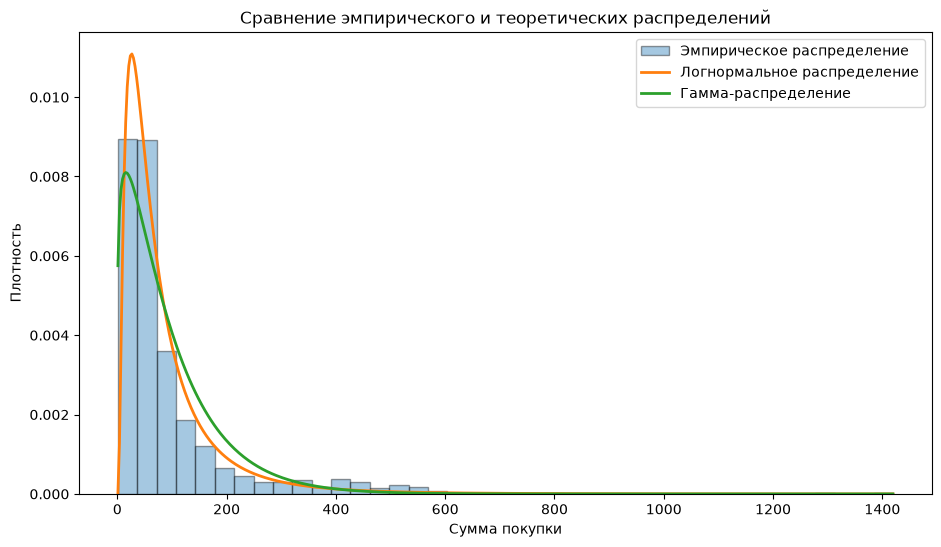

In [47]:
# Создаём диапазон значений для теоретических распределений
x = np.linspace(buyers.min(), buyers.max(), 500)

# Рассчитываем плотности
lognorm_pdf = stats.lognorm.pdf(x, *lognorm_params)
gamma_pdf = stats.gamma.pdf(x, *gamma_params)

# Строим график
plt.figure(figsize=(11, 6))

plt.hist(
    buyers,
    bins=40,
    density=True,
    alpha=0.4,
    edgecolor="black",
    label="Эмпирическое распределение"
)

plt.plot(
    x,
    lognorm_pdf,
    linewidth=2,
    label="Логнормальное распределение"
)

plt.plot(
    x,
    gamma_pdf,
    linewidth=2,
    label="Гамма-распределение"
)

plt.title("Сравнение эмпирического и теоретических распределений")
plt.xlabel("Сумма покупки")
plt.ylabel("Плотность")
plt.legend()
plt.show()

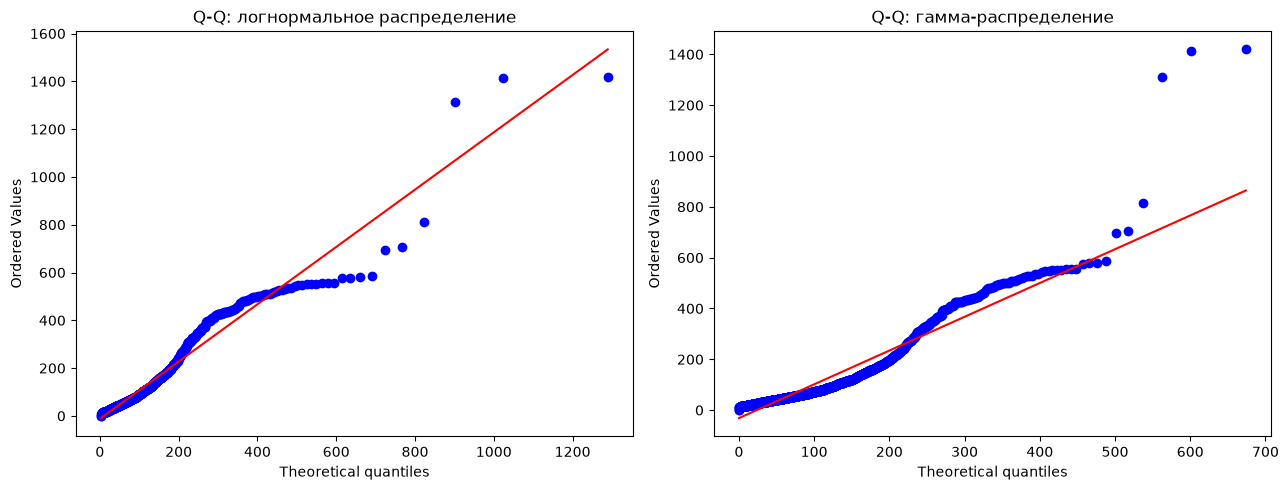

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Q-Q-график для логнормального распределения
stats.probplot(
    buyers,
    dist=stats.lognorm,
    sparams=(lognorm_params[0], 0, lognorm_params[2]),
    plot=axes[0]
)

axes[0].set_title("Q-Q: логнормальное распределение")

# Q-Q-график для гамма-распределения
stats.probplot(
    buyers,
    dist=stats.gamma,
    sparams=(gamma_params[0], 0, gamma_params[2]),
    plot=axes[1]
)

axes[1].set_title("Q-Q: гамма-распределение")

plt.tight_layout()
plt.show()

In [50]:
# Рассчитываем логарифм правдоподобия
loglik_lognorm = np.sum(stats.lognorm.logpdf(buyers, *lognorm_params))
loglik_gamma = np.sum(stats.gamma.logpdf(buyers, *gamma_params))

# Число оцениваемых параметров — 2 в каждой модели
k = 2
n = len(buyers)

# Рассчитываем AIC
aic_lognorm = 2 * k - 2 * loglik_lognorm
aic_gamma = 2 * k - 2 * loglik_gamma

# KS-тесты с оценёнными параметрами
ks_lognorm = stats.kstest(
    buyers, "lognorm", args=lognorm_params
)

ks_gamma = stats.kstest(
    buyers, "gamma", args=gamma_params
)

# Итоговая таблица
distribution_comparison = pd.DataFrame({
    "Распределение": ["Логнормальное", "Гамма"],
    "AIC": [aic_lognorm, aic_gamma],
    "KS statistic": [ks_lognorm.statistic, ks_gamma.statistic],
    "KS p-value": [ks_lognorm.pvalue, ks_gamma.pvalue]
})

display(distribution_comparison.round(4))

,Распределение,AIC,KS statistic,KS p-value
0,Логнормальное,19724.3277,0.067,0.0
1,Гамма,20222.0018,0.138,0.0


In [51]:
# Истинное среднее генеральной совокупности
true_mean = df["purchase_amount"].mean()

# Размеры выборок
sample_sizes = [10, 50, 200]

# Количество повторений
num_simulations = 1000

# Результаты
bias_results = {}

rng = np.random.default_rng(42)

for n in sample_sizes:

    biases = []

    for _ in range(num_simulations):

        # Случайная выборка без возвращения
        sample = rng.choice(population, size=n, replace=False)

        # Рассчитываем смещение среднего
        bias = sample.mean() - true_mean

        biases.append(bias)

    bias_results[n] = np.array(biases)

print("Истинное среднее:", round(true_mean, 2))

Истинное среднее: 34.93


In [52]:
import numpy as np
import pandas as pd

# Истинное среднее генеральной совокупности
true_mean = df["purchase_amount"].mean()

# Размеры выборок
sample_sizes = [10, 50, 200]

# Количество повторений
num_simulations = 1000

# Генератор случайных чисел
rng = np.random.default_rng(42)

# Список для итоговой таблицы
results = []

# Повторяем моделирование для каждого размера выборки
for n in sample_sizes:

    biases = []

    for _ in range(num_simulations):

        # Случайно выбираем наблюдения
        sample = rng.choice(population, size=n, replace=False)

        # Рассчитываем отклонение среднего от истинного значения
        bias = sample.mean() - true_mean

        biases.append(bias)

    # Сохраняем показатели
    results.append({
        "Размер выборки": n,
        "Среднее смещение": np.mean(biases),
        "Среднее абсолютное отклонение": np.mean(np.abs(biases)),
        "Стандартное отклонение смещения": np.std(biases, ddof=1)
    })

# Формируем и выводим таблицу
bias_table = pd.DataFrame(results)

display(bias_table.round(3))

,Размер выборки,Среднее смещение,Среднее абсолютное отклонение,Стандартное отклонение смещения
0,10,-1.117,21.643,28.205
1,50,0.493,9.280,11.879
2,200,0.093,4.653,5.841


In [53]:
import pandas as pd
import numpy as np

# Создаём копию данных для бизнес-анализа
business_df = df.copy()

# Формируем возрастные группы
business_df["Возрастная группа"] = pd.cut(
    business_df["age"],
    bins=[0, 19, 30, 45, 60, 120],
    labels=["До 19", "20–30", "31–45", "46–60", "Старше 60"]
)

# Формируем группы по времени на сайте
business_df["Время на сайте"] = pd.cut(
    business_df["time_on_site_s"],
    bins=[0, 120, 300, 600, np.inf],
    labels=["До 2 минут", "2–5 минут", "5–10 минут", "Более 10 минут"]
)

# Формируем группы по количеству просмотренных страниц
business_df["Просмотренные страницы"] = pd.cut(
    business_df["pages_visited"],
    bins=[0, 3, 6, 9, np.inf],
    labels=["1–3 страницы", "4–6 страниц", "7–9 страниц", "Более 9 страниц"]
)


# Функция расчёта бизнес-показателей
def business_metrics(data, column):

    result = (
        data.groupby(column, observed=True)
        .agg(
            Количество_клиентов=("customer_id", "count"),
            Конверсия=("converted", "mean"),
            Выручка_на_посетителя=("purchase_amount", "mean")
        )
    )

    # Средний чек рассчитываем только среди покупателей
    buyers_group = (
        data[data["converted"] == 1]
        .groupby(column, observed=True)["purchase_amount"]
        .mean()
    )

    result["Средний_чек"] = buyers_group

    result["Конверсия"] *= 100

    # Исключаем слишком маленькие группы из итогового сравнения
    result = result[result["Количество_клиентов"] >= 30]

    return result.sort_values(
        "Выручка_на_посетителя",
        ascending=False
    )


# Анализируем различные факторы
factors = [
    "region",
    "traffic_source",
    "campaign",
    "Возрастная группа",
    "Время на сайте",
    "Просмотренные страницы"
]

# Выводим результаты
for factor in factors:

    print("\n" + "=" * 70)
    print("ФАКТОР:", factor)
    print("=" * 70)

    display(business_metrics(business_df, factor).round(2))


ФАКТОР: region


,Количество_клиентов,Конверсия,Выручка_на_посетителя,Средний_чек
region,,,,
East,1579,35.15,36.65,104.28
South,1235,37.25,35.66,95.73
West,1011,37.59,34.51,91.80
North,1175,36.17,32.20,89.03



ФАКТОР: traffic_source


,Количество_клиентов,Конверсия,Выручка_на_посетителя,Средний_чек
traffic_source,,,,
Referral,513,41.33,39.47,95.51
Email,737,36.50,35.65,97.67
PaidAds,1551,34.69,34.45,99.30
Organic,2199,36.43,33.97,93.25



ФАКТОР: campaign


,Количество_клиентов,Конверсия,Выручка_на_посетителя,Средний_чек
campaign,,,,
CAMP7,219,38.81,44.08,113.58
CAMP1,223,34.53,39.29,113.78
CAMP5,215,38.60,35.05,90.79
CAMP4,221,31.67,34.23,108.08
CAMP6,205,39.02,33.42,85.65
CAMP3,212,31.13,31.91,102.51
CAMP2,256,30.08,24.58,81.70


... (2 outputs left out)


ФАКТОР: Время на сайте


,Количество_клиентов,Конверсия,Выручка_на_посетителя,Средний_чек
Время на сайте,,,,
Более 10 минут,770,71.17,69.41,97.53
5–10 минут,1784,42.26,40.34,95.44
2–5 минут,1729,24.29,23.10,95.11
До 2 минут,717,13.67,12.95,94.73



ФАКТОР: Просмотренные страницы


,Количество_клиентов,Конверсия,Выручка_на_посетителя,Средний_чек
Просмотренные страницы,,,,
1–3 страницы,657,37.75,37.21,98.58
Более 9 страниц,342,36.26,36.01,99.31
4–6 страниц,2426,36.73,35.41,96.41
7–9 страниц,1575,35.37,33.00,93.32


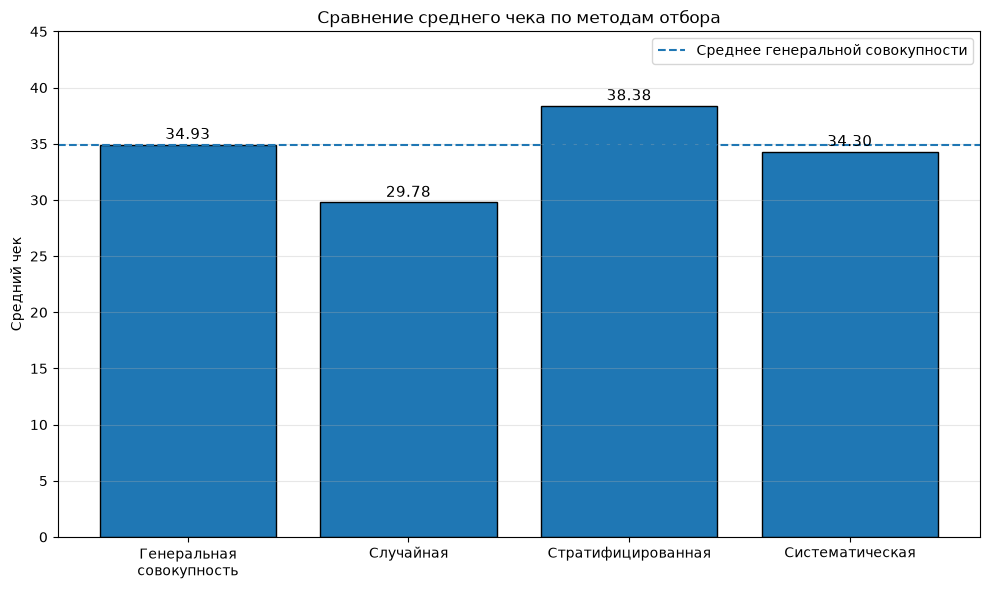

In [54]:
import matplotlib.pyplot as plt
import numpy as np

# Названия методов отбора
methods = [
    "Генеральная\nсовокупность",
    "Случайная",
    "Стратифицированная",
    "Систематическая"
]

# Средние чеки
means = [34.93, 29.78, 38.38, 34.30]

# Строим график
plt.figure(figsize=(10, 6))

bars = plt.bar(methods, means, edgecolor="black")

# Добавляем значения над столбцами
for bar, value in zip(bars, means):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}",
        ha="center",
        fontsize=11
    )

plt.axhline(
    y=34.93,
    linestyle="--",
    label="Среднее генеральной совокупности"
)

plt.title("Сравнение среднего чека по методам отбора")
plt.ylabel("Средний чек")
plt.ylim(0, 45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

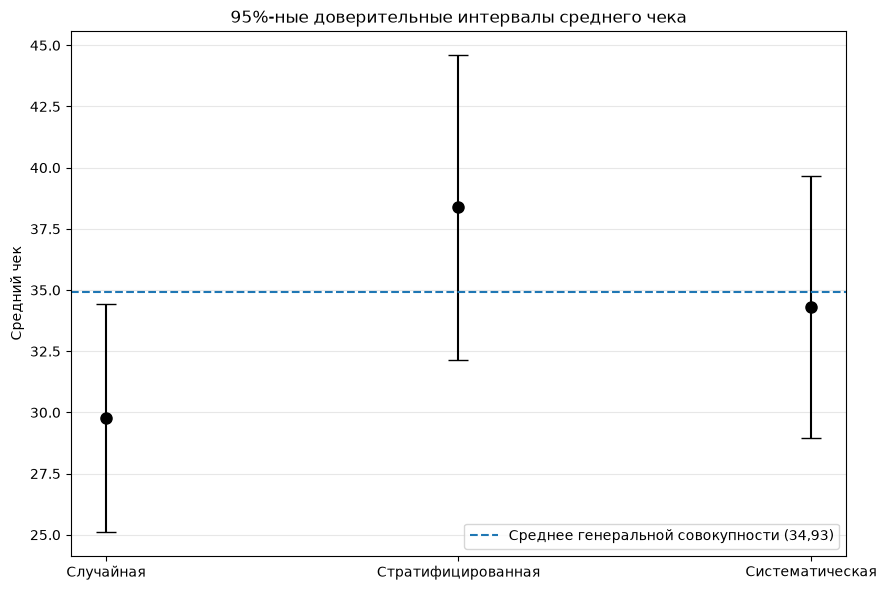

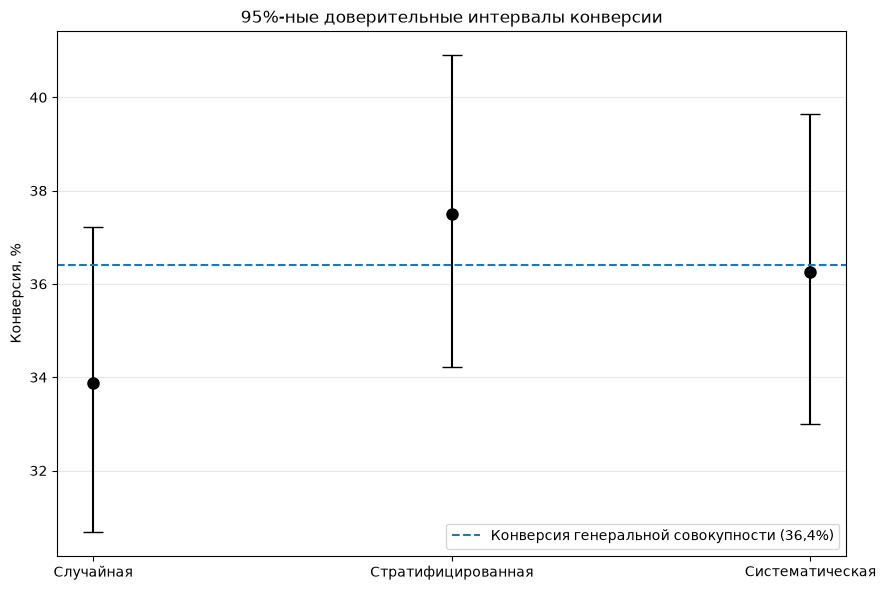

Скачать график 2:


/drive/graph_2_mean_confidence_intervals.png

Скачать график 3:


/drive/graph_3_conversion_confidence_intervals.png

In [55]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, FileLink

# ==========================================
# ГРАФИК 2. Доверительные интервалы среднего чека
# ==========================================

methods = ["Случайная", "Стратифицированная", "Систематическая"]

means = np.array([29.78, 38.38, 34.30])
ci_lower = np.array([25.11, 32.15, 28.95])
ci_upper = np.array([34.45, 44.61, 39.65])

# Рассчитываем длину нижней и верхней частей интервала
errors = np.array([
    means - ci_lower,
    ci_upper - means
])

plt.figure(figsize=(9, 6))

plt.errorbar(
    methods,
    means,
    yerr=errors,
    fmt="o",
    capsize=7,
    markersize=8,
    color="black"
)

plt.axhline(
    y=34.93,
    linestyle="--",
    label="Среднее генеральной совокупности (34,93)"
)

plt.title("95%-ные доверительные интервалы среднего чека")
plt.ylabel("Средний чек")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("graph_2_mean_confidence_intervals.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ГРАФИК 3. Доверительные интервалы конверсии
# ==========================================

conversion = np.array([33.88, 37.50, 36.25])
ci_lower = np.array([30.68, 34.21, 32.99])
ci_upper = np.array([37.22, 40.91, 39.64])

errors = np.array([
    conversion - ci_lower,
    ci_upper - conversion
])

plt.figure(figsize=(9, 6))

plt.errorbar(
    methods,
    conversion,
    yerr=errors,
    fmt="o",
    capsize=7,
    markersize=8,
    color="black"
)

plt.axhline(
    y=36.4,
    linestyle="--",
    label="Конверсия генеральной совокупности (36,4%)"
)

plt.title("95%-ные доверительные интервалы конверсии")
plt.ylabel("Конверсия, %")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("graph_3_conversion_confidence_intervals.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ССЫЛКИ ДЛЯ СКАЧИВАНИЯ ДВУХ КАРТИНОК
# ==========================================

print("Скачать график 2:")
display(FileLink("graph_2_mean_confidence_intervals.png"))

print("Скачать график 3:")
display(FileLink("graph_3_conversion_confidence_intervals.png"))

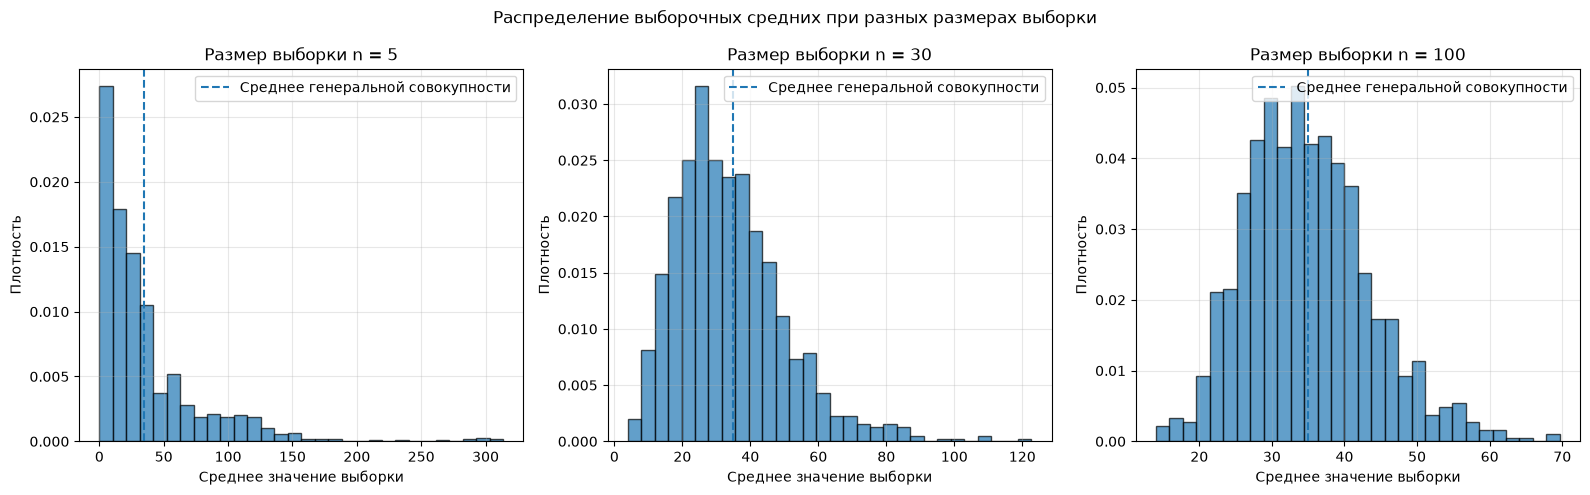

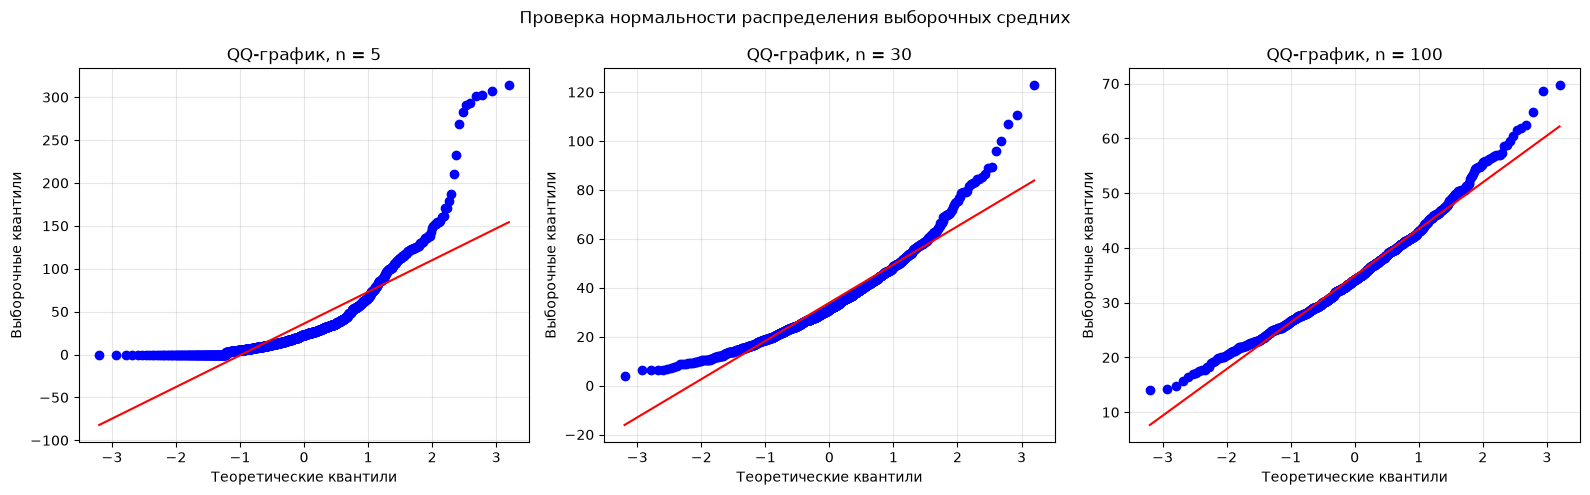

Скачать график 4 — гистограммы:


/drive/graph_4_histograms.png

Скачать график 5 — QQ-графики:


/drive/graph_5_qqplots.png

In [57]:
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, FileLink

# Размеры выборок
sample_sizes = [5, 30, 100]

# ==========================================
# ГРАФИК 4. ГИСТОГРАММЫ СРЕДНИХ ЗНАЧЕНИЙ
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, n in zip(axes, sample_sizes):
    values = sample_means[n]

    # Гистограмма
    ax.hist(values, bins=30, density=True, edgecolor="black", alpha=0.7)

    # Вертикальная линия среднего генеральной совокупности
    ax.axvline(
        x=34.93,
        linestyle="--",
        label="Среднее генеральной совокупности"
    )

    ax.set_title(f"Размер выборки n = {n}")
    ax.set_xlabel("Среднее значение выборки")
    ax.set_ylabel("Плотность")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Распределение выборочных средних при разных размерах выборки")
plt.tight_layout()

# Сохраняем первую картинку
plt.savefig("graph_4_histograms.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ГРАФИК 5. QQ-ГРАФИКИ
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, n in zip(axes, sample_sizes):
    values = sample_means[n]

    # QQ-график для проверки нормальности
    stats.probplot(values, dist="norm", plot=ax)

    ax.set_title(f"QQ-график, n = {n}")
    ax.set_xlabel("Теоретические квантили")
    ax.set_ylabel("Выборочные квантили")
    ax.grid(alpha=0.3)

plt.suptitle("Проверка нормальности распределения выборочных средних")
plt.tight_layout()

# Сохраняем вторую картинку
plt.savefig("graph_5_qqplots.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ССЫЛКИ ДЛЯ СКАЧИВАНИЯ
# ==========================================

print("Скачать график 4 — гистограммы:")
display(FileLink("graph_4_histograms.png"))

print("Скачать график 5 — QQ-графики:")
display(FileLink("graph_5_qqplots.png"))

Размер датасета: (5000, 14)


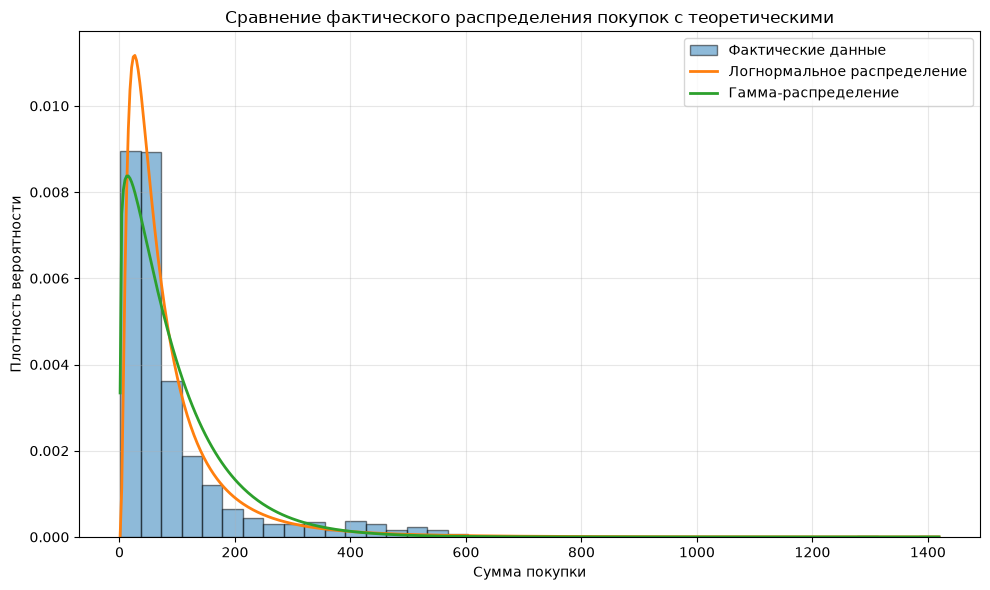

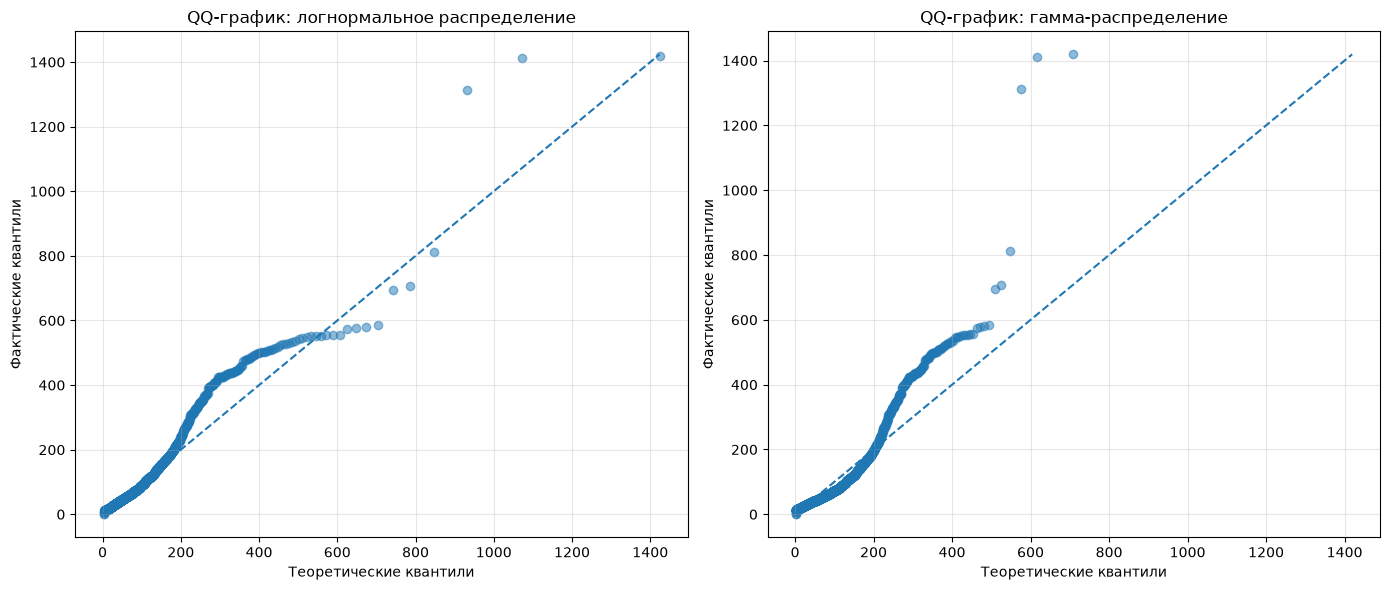

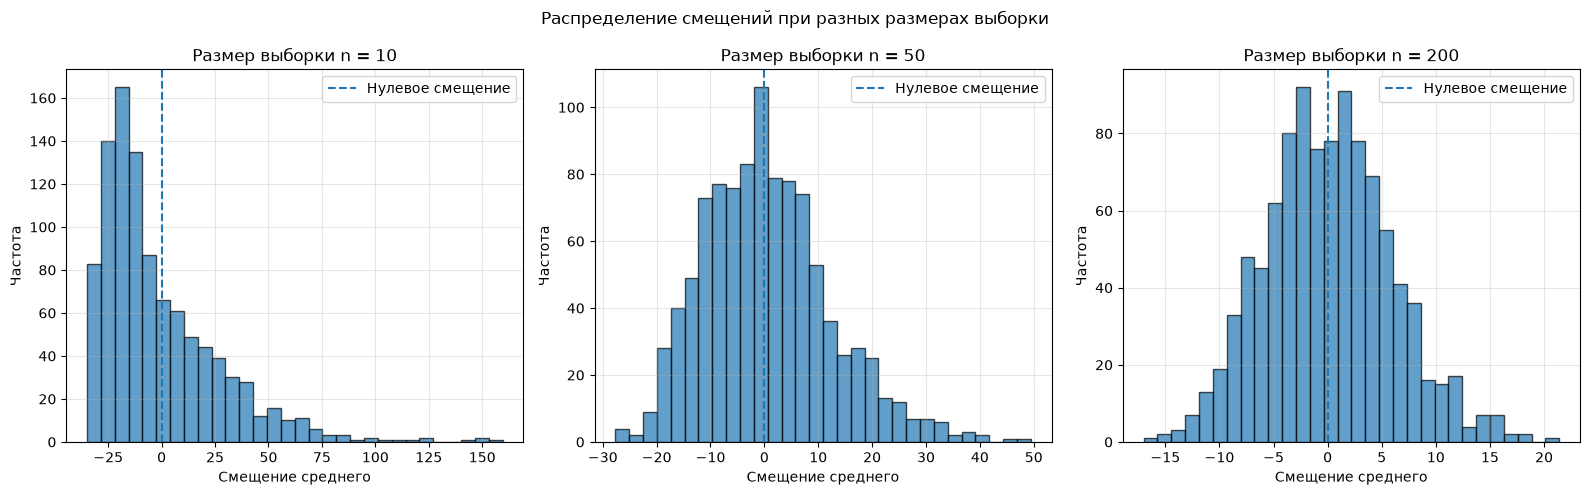

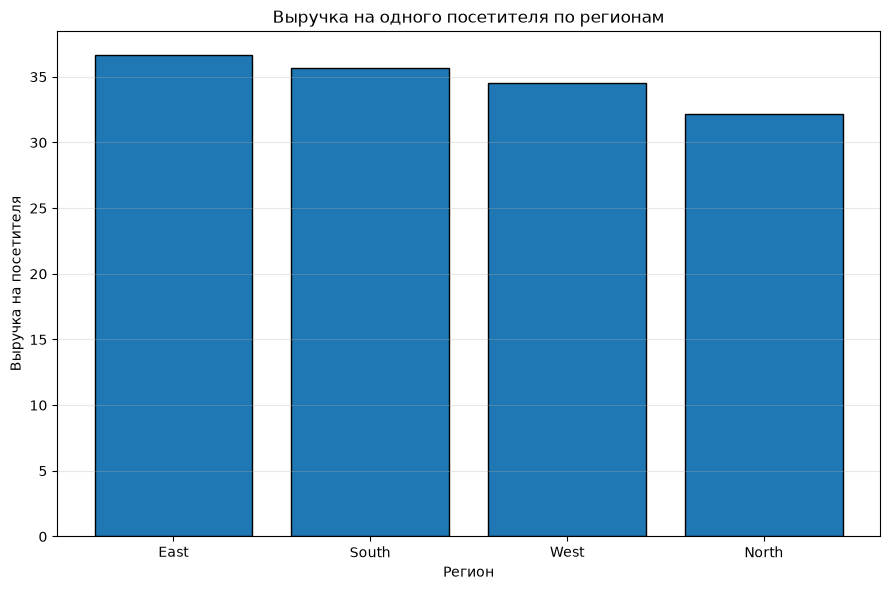

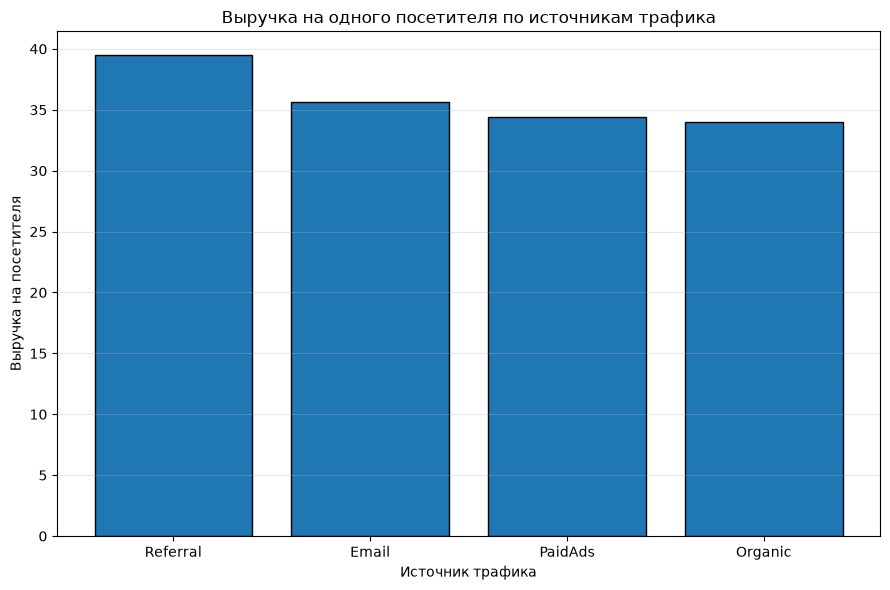

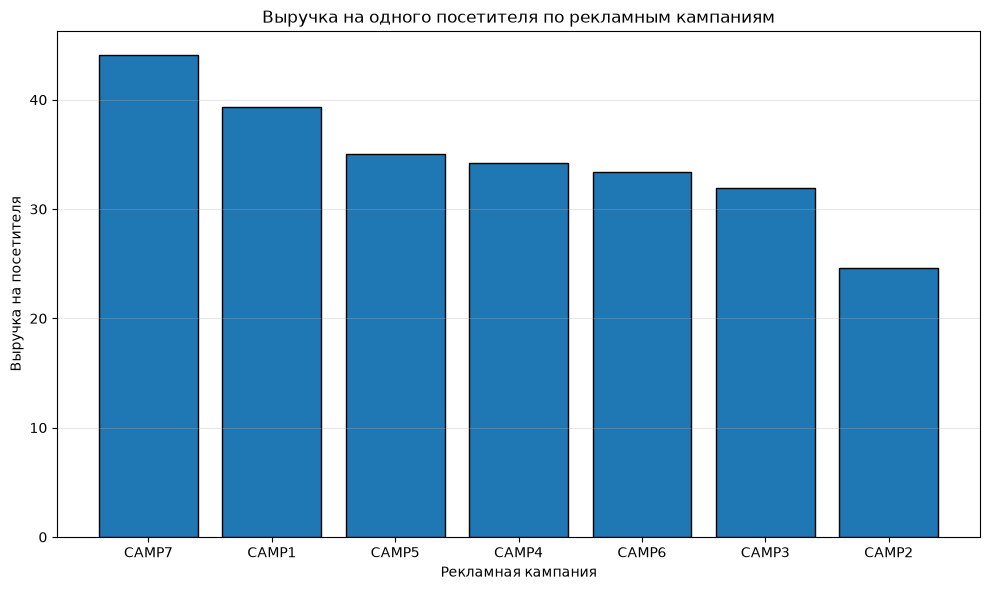

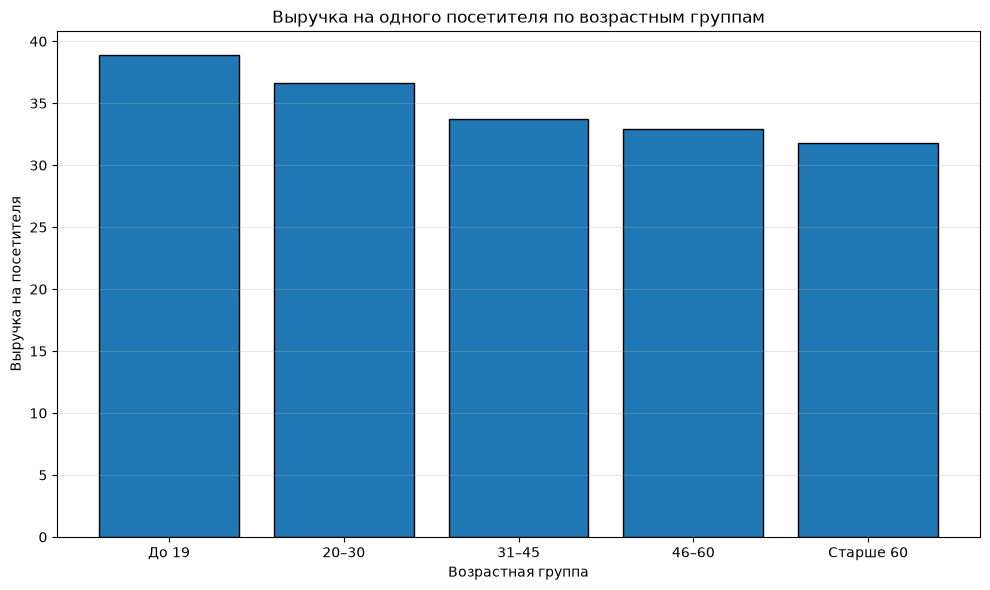

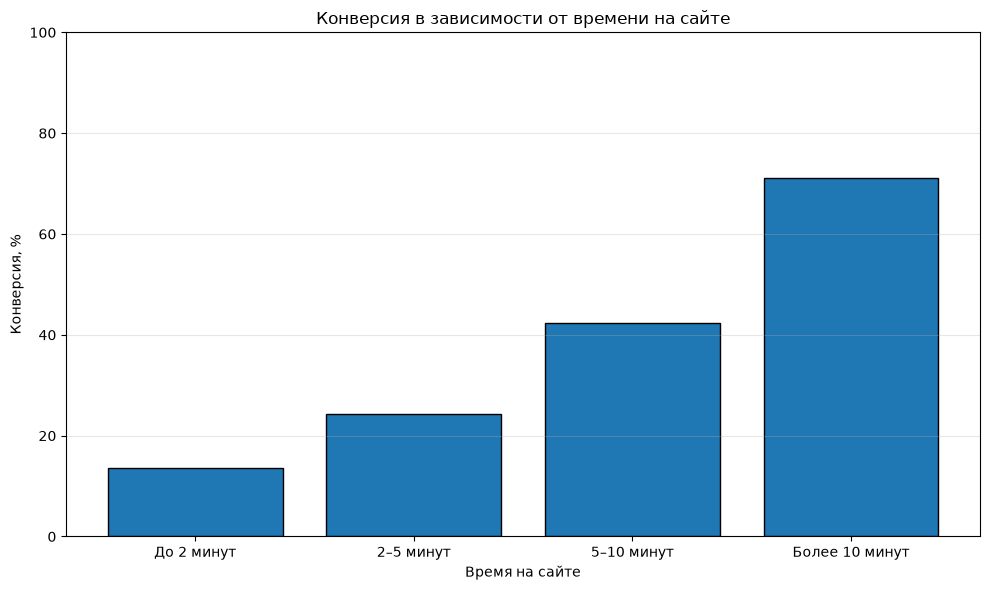

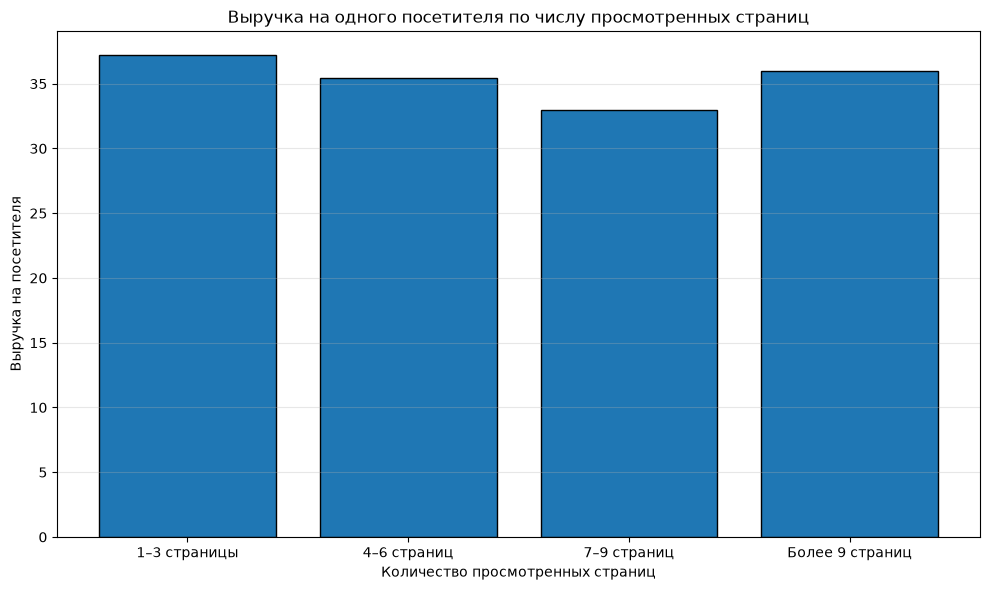

Все графики построены. Ссылки для скачивания:
graph_6_distributions.png


/drive/graph_6_distributions.png

graph_7_qq_distributions.png


/drive/graph_7_qq_distributions.png

graph_8_bias.png


/drive/graph_8_bias.png

... (8 outputs left out)

graph_13_time.png


/drive/graph_13_time.png

graph_14_pages.png


/drive/graph_14_pages.png

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
from IPython.display import display, FileLink

# Фиксируем генератор случайных чисел для воспроизводимости
rng = np.random.default_rng(42)

# Проверяем исходные данные
print("Размер датасета:", df.shape)

# ==========================================
# ГРАФИК 6. СРАВНЕНИЕ ТЕОРЕТИЧЕСКИХ РАСПРЕДЕЛЕНИЙ
# ==========================================

# Берём только покупателей с положительной суммой покупки
buyers = df.loc[
    (df["converted"] == 1) & (df["purchase_amount"] > 0),
    "purchase_amount"
].dropna()

# Подбираем параметры распределений
lognorm_params = stats.lognorm.fit(buyers)
gamma_params = stats.gamma.fit(buyers)

# Диапазон значений для плотностей
x = np.linspace(buyers.min(), buyers.max(), 500)

plt.figure(figsize=(10, 6))

plt.hist(
    buyers,
    bins=40,
    density=True,
    alpha=0.5,
    edgecolor="black",
    label="Фактические данные"
)

plt.plot(
    x,
    stats.lognorm.pdf(x, *lognorm_params),
    linewidth=2,
    label="Логнормальное распределение"
)

plt.plot(
    x,
    stats.gamma.pdf(x, *gamma_params),
    linewidth=2,
    label="Гамма-распределение"
)

plt.title("Сравнение фактического распределения покупок с теоретическими")
plt.xlabel("Сумма покупки")
plt.ylabel("Плотность вероятности")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("graph_6_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ГРАФИК 7. QQ-ГРАФИКИ ДЛЯ ДВУХ РАСПРЕДЕЛЕНИЙ
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sorted_buyers = np.sort(buyers)
n = len(sorted_buyers)

# Эмпирические вероятности
probabilities = (np.arange(1, n + 1) - 0.5) / n

# Теоретические квантили
lognorm_quantiles = stats.lognorm.ppf(
    probabilities, *lognorm_params
)

gamma_quantiles = stats.gamma.ppf(
    probabilities, *gamma_params
)

# Логнормальное распределение
axes[0].scatter(lognorm_quantiles, sorted_buyers, alpha=0.5)

min_val = min(lognorm_quantiles.min(), sorted_buyers.min())
max_val = max(lognorm_quantiles.max(), sorted_buyers.max())

axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

axes[0].set_title("QQ-график: логнормальное распределение")
axes[0].set_xlabel("Теоретические квантили")
axes[0].set_ylabel("Фактические квантили")
axes[0].grid(alpha=0.3)

# Гамма-распределение
axes[1].scatter(gamma_quantiles, sorted_buyers, alpha=0.5)

min_val = min(gamma_quantiles.min(), sorted_buyers.min())
max_val = max(gamma_quantiles.max(), sorted_buyers.max())

axes[1].plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

axes[1].set_title("QQ-график: гамма-распределение")
axes[1].set_xlabel("Теоретические квантили")
axes[1].set_ylabel("Фактические квантили")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("graph_7_qq_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ГРАФИК 8. РАСПРЕДЕЛЕНИЕ СМЕЩЕНИЙ
# ==========================================

population = df["purchase_amount"].dropna().to_numpy()
population_mean = population.mean()

sample_sizes = [10, 50, 200]
bias_results = {}

for n_sample in sample_sizes:
    biases = []

    for _ in range(1000):
        sample = rng.choice(
            population,
            size=n_sample,
            replace=False
        )

        biases.append(sample.mean() - population_mean)

    bias_results[n_sample] = biases

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, n_sample in zip(axes, sample_sizes):
    biases = bias_results[n_sample]

    ax.hist(
        biases,
        bins=30,
        edgecolor="black",
        alpha=0.7
    )

    ax.axvline(0, linestyle="--", label="Нулевое смещение")

    ax.set_title(f"Размер выборки n = {n_sample}")
    ax.set_xlabel("Смещение среднего")
    ax.set_ylabel("Частота")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Распределение смещений при разных размерах выборки")
plt.tight_layout()

plt.savefig("graph_8_bias.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ПОДГОТОВКА ДАННЫХ ДЛЯ БИЗНЕС-ГРАФИКОВ
# ==========================================

def calculate_metrics(data, group_column):
    """Рассчитывает конверсию и выручку на одного посетителя."""

    result = data.groupby(group_column, observed=False).agg(
        customers=("customer_id", "count"),
        conversion=("converted", "mean"),
        revenue_per_visitor=("purchase_amount", "mean")
    )

    result["conversion"] *= 100

    return result


# ==========================================
# ГРАФИК 9. ВЫРУЧКА НА ПОСЕТИТЕЛЯ ПО РЕГИОНАМ
# ==========================================

region_metrics = calculate_metrics(df, "region").sort_values(
    "revenue_per_visitor",
    ascending=False
)

plt.figure(figsize=(9, 6))

plt.bar(
    region_metrics.index.astype(str),
    region_metrics["revenue_per_visitor"],
    edgecolor="black"
)

plt.title("Выручка на одного посетителя по регионам")
plt.xlabel("Регион")
plt.ylabel("Выручка на посетителя")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("graph_9_regions.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ГРАФИК 10. ВЫРУЧКА НА ПОСЕТИТЕЛЯ ПО ИСТОЧНИКАМ
# ==========================================

traffic_metrics = calculate_metrics(df, "traffic_source").sort_values(
    "revenue_per_visitor",
    ascending=False
)

plt.figure(figsize=(9, 6))

plt.bar(
    traffic_metrics.index.astype(str),
    traffic_metrics["revenue_per_visitor"],
    edgecolor="black"
)

plt.title("Выручка на одного посетителя по источникам трафика")
plt.xlabel("Источник трафика")
plt.ylabel("Выручка на посетителя")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("graph_10_traffic.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ГРАФИК 11. ВЫРУЧКА НА ПОСЕТИТЕЛЯ ПО КАМПАНИЯМ
# ==========================================

campaign_data = df.dropna(subset=["campaign"])

campaign_metrics = calculate_metrics(
    campaign_data,
    "campaign"
).sort_values("revenue_per_visitor", ascending=False)

plt.figure(figsize=(10, 6))

plt.bar(
    campaign_metrics.index.astype(str),
    campaign_metrics["revenue_per_visitor"],
    edgecolor="black"
)

plt.title("Выручка на одного посетителя по рекламным кампаниям")
plt.xlabel("Рекламная кампания")
plt.ylabel("Выручка на посетителя")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("graph_11_campaigns.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ГРАФИК 12. ВЫРУЧКА НА ПОСЕТИТЕЛЯ ПО ВОЗРАСТУ
# ==========================================

age_data = df.copy()

age_data["age_group"] = pd.cut(
    age_data["age"],
    bins=[0, 19, 30, 45, 60, np.inf],
    labels=["До 19", "20–30", "31–45", "46–60", "Старше 60"],
    include_lowest=True
)

age_metrics = calculate_metrics(age_data, "age_group")

plt.figure(figsize=(10, 6))

plt.bar(
    age_metrics.index.astype(str),
    age_metrics["revenue_per_visitor"],
    edgecolor="black"
)

plt.title("Выручка на одного посетителя по возрастным группам")
plt.xlabel("Возрастная группа")
plt.ylabel("Выручка на посетителя")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("graph_12_age.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ГРАФИК 13. КОНВЕРСИЯ В ЗАВИСИМОСТИ ОТ ВРЕМЕНИ НА САЙТЕ
# ==========================================

time_data = df.copy()

time_data["time_group"] = pd.cut(
    time_data["time_on_site_s"],
    bins=[-np.inf, 120, 300, 600, np.inf],
    labels=["До 2 минут", "2–5 минут", "5–10 минут", "Более 10 минут"]
)

time_metrics = calculate_metrics(time_data, "time_group")

plt.figure(figsize=(10, 6))

plt.bar(
    time_metrics.index.astype(str),
    time_metrics["conversion"],
    edgecolor="black"
)

plt.title("Конверсия в зависимости от времени на сайте")
plt.xlabel("Время на сайте")
plt.ylabel("Конверсия, %")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("graph_13_time.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ГРАФИК 14. ВЫРУЧКА НА ПОСЕТИТЕЛЯ ПО ЧИСЛУ СТРАНИЦ
# ==========================================

pages_data = df.copy()

pages_data["pages_group"] = pd.cut(
    pages_data["pages_visited"],
    bins=[0, 3, 6, 9, np.inf],
    labels=["1–3 страницы", "4–6 страниц", "7–9 страниц", "Более 9 страниц"],
    include_lowest=True
)

pages_metrics = calculate_metrics(pages_data, "pages_group")

plt.figure(figsize=(10, 6))

plt.bar(
    pages_metrics.index.astype(str),
    pages_metrics["revenue_per_visitor"],
    edgecolor="black"
)

plt.title("Выручка на одного посетителя по числу просмотренных страниц")
plt.xlabel("Количество просмотренных страниц")
plt.ylabel("Выручка на посетителя")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("graph_14_pages.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# ССЫЛКИ ДЛЯ СКАЧИВАНИЯ ВСЕХ 9 ГРАФИКОВ
# ==========================================

files = [
    "graph_6_distributions.png",
    "graph_7_qq_distributions.png",
    "graph_8_bias.png",
    "graph_9_regions.png",
    "graph_10_traffic.png",
    "graph_11_campaigns.png",
    "graph_12_age.png",
    "graph_13_time.png",
    "graph_14_pages.png"
]

print("Все графики построены. Ссылки для скачивания:")

for file in files:
    print(file)
    display(FileLink(file))